### Import libraries

In [1]:
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


### Set paths

In [2]:
def find_project_root():

    current_path = Path.cwd().resolve()

    for path in [current_path, *current_path.parents]:

        if (
            (path / ".git").exists()
            or (
                (path / "data" / "processed").is_dir()
                and (path / "models").is_dir()
            )
        ):
            return path

    raise FileNotFoundError(
        "Project root not found. "
        "Please run this notebook inside the project directory."
    )


ROOT = find_project_root()

DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODEL_DIR = ROOT / "models"
EVALUATION_DIR = ROOT / "evaluation"

EVALUATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = MODEL_DIR / "rice_disease_model.pth"
TEST_PATH = PROCESSED_DIR / "test.csv"

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Trained model not found: {MODEL_PATH}"
    )

if not TEST_PATH.is_file():
    raise FileNotFoundError(
        f"Test dataset not found: {TEST_PATH}"
    )

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Selected Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU


### Load model and class names

In [3]:
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

class_to_idx = checkpoint["class_to_idx"]

idx_to_class = {
    index: name
    for name, index in class_to_idx.items()
}

num_classes = len(class_to_idx)

model = efficientnet_b0(weights=None)

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    num_classes
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

print("Model loaded successfully!")
print("Classes:", idx_to_class)


Model loaded successfully!
Classes: {0: 'Healthy', 1: 'bacterial_leaf_blight', 2: 'brown_spot', 3: 'leaf_blast', 4: 'leaf_scald', 5: 'narrow_brown_spot', 6: 'neck_blast', 7: 'rice_hispa', 8: 'sheath_blight', 9: 'tungro'}


### Load test images

In [4]:
test_df = pd.read_csv(TEST_PATH)

IMAGE_SIZE = checkpoint["image_size"]

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=checkpoint["mean"],
        std=checkpoint["std"]
    )
])


class RiceTestDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = ROOT / row["image_path"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        image = test_transform(image)

        label = class_to_idx[row["label"]]

        return image, label


test_dataset = RiceTestDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Test images:", len(test_dataset))


Test images: 1007


### Predict all test images

In [5]:
all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

print("Prediction completed!")


Prediction completed!


### Calculate model performance

In [6]:
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print("MODEL PERFORMANCE")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")


MODEL PERFORMANCE
Accuracy:  0.9841
Precision: 0.9827
Recall:    0.9846
F1 Score:  0.9831


### Classification report

In [7]:
class_names = [
    idx_to_class[i]
    for i in range(num_classes)
]

report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(num_classes)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

accuracy = report.pop("accuracy")
report_df = pd.DataFrame(report).transpose()
report_df.loc["accuracy"] = {
    "precision": np.nan,
    "recall": np.nan,
    "f1-score": accuracy,
    "support": len(all_labels),
}

from IPython.display import display as ipy_display
ipy_display(report_df)

report_df.to_csv(
    EVALUATION_DIR / "classification_report.csv"
)


,precision,recall,f1-score,support
Healthy,1.000000,1.000000,1.000000,113.000000
bacterial_leaf_blight,1.000000,1.000000,1.000000,118.000000
brown_spot,0.990991,0.964912,0.977778,114.000000
leaf_blast,0.876404,1.000000,0.934132,78.000000
leaf_scald,0.986667,0.961039,0.973684,77.000000
narrow_brown_spot,0.981651,0.930435,0.955357,115.000000
neck_blast,1.000000,1.000000,1.000000,102.000000
rice_hispa,0.991379,1.000000,0.995671,115.000000
sheath_blight,1.000000,0.989130,0.994536,92.000000
tungro,1.000000,1.000000,1.000000,83.000000


### Confusion matrix

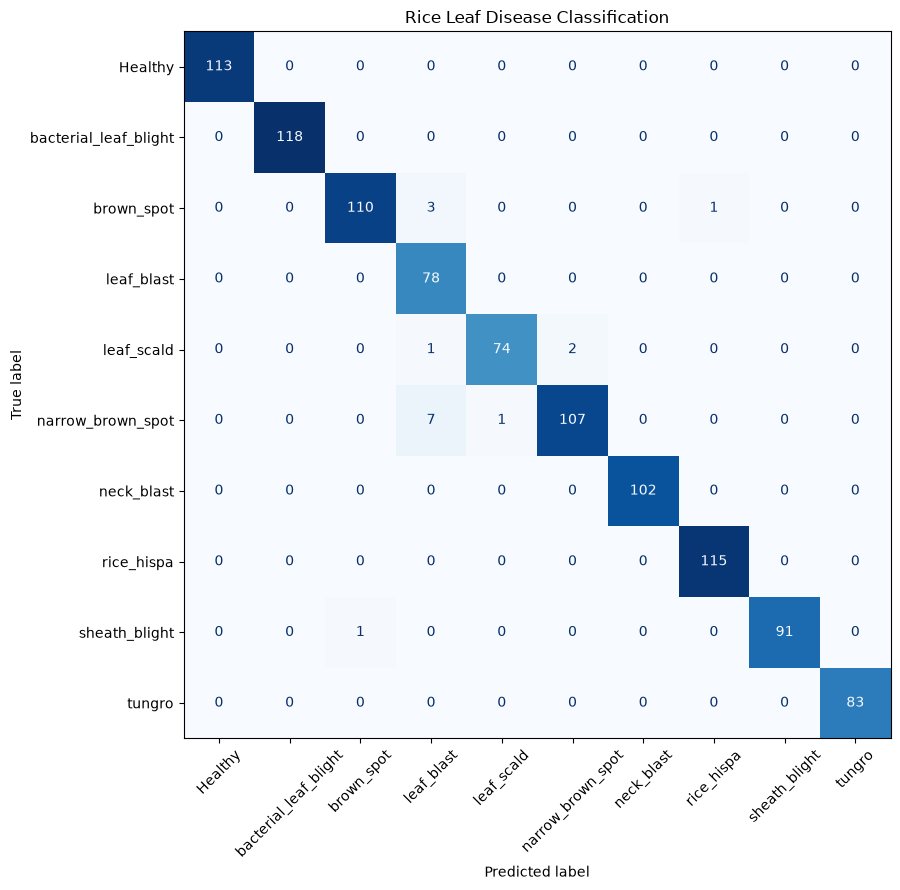

In [8]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(num_classes))
)

fig, ax = plt.subplots(figsize=(11, 9))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

cm_display.plot(
    cmap="Blues",
    xticks_rotation=45,
    ax=ax,
    colorbar=False
)

plt.title("Rice Leaf Disease Classification")
plt.tight_layout()
plt.show()

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(EVALUATION_DIR / "confusion_matrix.csv")

